# Practical: Data Collection, Importing, Cleaning, and Preprocessing

**Aim:** To collect, import, clean, and preprocess datasets by handling missing values, removing duplicates, detecting outliers, and standardizing data.

**Dataset:** Iris Dataset

**Libraries:** pandas, numpy, matplotlib, seaborn, scikit-learn

## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 2. Data Collection and Importing

Load the Iris dataset from scikit-learn and convert it into a pandas DataFrame. The dataset contains 150 flower records, four numerical features, and one target column.

In [2]:
iris = load_iris(as_frame=True)
data = iris.frame.copy()

# Replace numeric target labels with readable species names
data['target'] = data['target'].map(dict(enumerate(iris.target_names)))

print('Dataset imported successfully!')
display(data.head())

Dataset imported successfully!


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Understanding the Dataset

In [3]:
print('Shape of dataset:', data.shape)
print('\nColumn names:')
print(data.columns.tolist())

print('\nDataset information:')
data.info()

print('\nStatistical summary:')
display(data.describe())

print('\nSpecies count:')
print(data['target'].value_counts())

Shape of dataset: (150, 5)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species count:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 4. Check and Handle Missing Values

First, count missing values in every column. If any are present, fill numerical columns with their median. The original Iris dataset normally contains no missing values, so this step may make no changes.

In [4]:
print('Missing values before cleaning:')
print(data.isnull().sum())

numeric_columns = data.select_dtypes(include=np.number).columns
for column in numeric_columns:
    data[column] = data[column].fillna(data[column].median())

print('\nMissing values after cleaning:')
print(data.isnull().sum())

Missing values before cleaning:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Missing values after cleaning:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


## 5. Remove Duplicate Records

In [5]:
duplicate_count = data.duplicated().sum()
print('Number of duplicate rows:', duplicate_count)

data = data.drop_duplicates().reset_index(drop=True)

print('Shape after removing duplicates:', data.shape)
print('Duplicates remaining:', data.duplicated().sum())

Number of duplicate rows: 1
Shape after removing duplicates: (149, 5)
Duplicates remaining: 0


## 6. Detect Outliers Using the IQR Method

The Interquartile Range (IQR) method identifies values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. Here, we detect outliers in the four numerical flower measurements.

In [6]:
feature_columns = data.select_dtypes(include=np.number).columns

outlier_counts = {}
for column in feature_columns:
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_mask = (data[column] < lower_bound) | (data[column] > upper_bound)
    outlier_counts[column] = int(outlier_mask.sum())

print('Outliers detected in each feature:')
print(pd.Series(outlier_counts, name='Outlier Count'))

Outliers detected in each feature:
sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
Name: Outlier Count, dtype: int64


## 7. Visualize Outliers Using Boxplots

Boxplots help visualize the spread of each feature and show possible outliers as individual points.

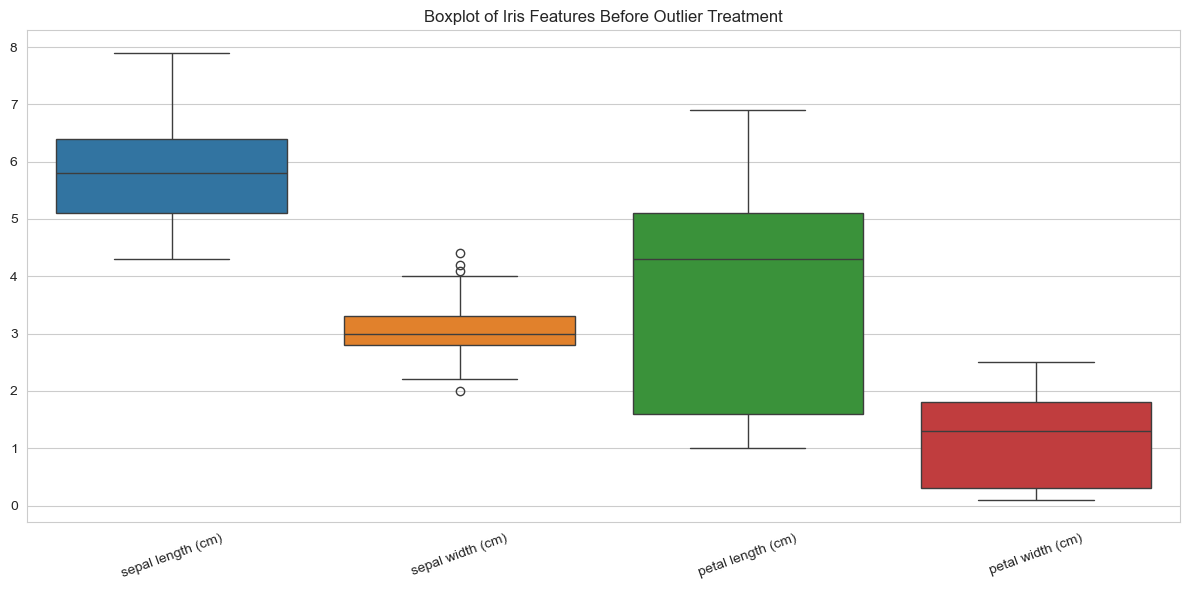

In [7]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data[feature_columns])
plt.title('Boxplot of Iris Features Before Outlier Treatment')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 8. Handle Outliers Using Capping

For this practical, cap values outside the IQR limits to the lower or upper boundary instead of deleting rows. This keeps all flower records. Outlier treatment is a choice; investigate unusual values before changing them in a real project.

In [8]:
for column in feature_columns:
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    data[column] = data[column].clip(lower=lower_bound, upper=upper_bound)

print('Outlier capping completed.')
display(data[feature_columns].describe())

Outlier capping completed.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.056376,3.748993,1.194631
std,0.830851,0.425825,1.767791,0.762622
min,4.300000,2.050000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.050000,6.900000,2.500000


## 9. Standardize the Numerical Features

StandardScaler transforms numerical features to have approximately zero mean and unit standard deviation. The target column is not standardized.

In [9]:
scaler = StandardScaler()

standardized_data = data.copy()
standardized_data[feature_columns] = scaler.fit_transform(data[feature_columns])

print('Standardized dataset:')
display(standardized_data.head())

print('\nMean of standardized features (approximately 0):')
print(standardized_data[feature_columns].mean().round(3))

print('\nStandard deviation of standardized features (approximately 1):')
print(standardized_data[feature_columns].std().round(3))

Standardized dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,-0.898033,1.045312,-1.333255,-1.308624,setosa
1,-1.139562,-0.132838,-1.333255,-1.308624,setosa
2,-1.381091,0.338422,-1.390014,-1.308624,setosa
3,-1.501855,0.102792,-1.276496,-1.308624,setosa
4,-1.018798,1.280942,-1.333255,-1.308624,setosa



Mean of standardized features (approximately 0):
sepal length (cm)    0.0
sepal width (cm)     0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64

Standard deviation of standardized features (approximately 1):
sepal length (cm)    1.003
sepal width (cm)     1.003
petal length (cm)    1.003
petal width (cm)     1.003
dtype: float64


## 10. Final Verification

In [10]:
print('Final dataset shape:', standardized_data.shape)
print('\nMissing values:')
print(standardized_data.isnull().sum())

print('\nDuplicate rows:', standardized_data.duplicated().sum())
print('\nFinal preprocessed dataset:')
display(standardized_data.head(10))

Final dataset shape: (149, 5)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Duplicate rows: 0

Final preprocessed dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,-0.898033,1.045312,-1.333255,-1.308624,setosa
1,-1.139562,-0.132838,-1.333255,-1.308624,setosa
2,-1.381091,0.338422,-1.390014,-1.308624,setosa
3,-1.501855,0.102792,-1.276496,-1.308624,setosa
4,-1.018798,1.280942,-1.333255,-1.308624,setosa
5,-0.535740,1.987832,-1.162979,-1.045486,setosa
6,-1.501855,0.809682,-1.333255,-1.177055,setosa
7,-1.018798,0.809682,-1.276496,-1.308624,setosa
8,-1.743384,-0.368468,-1.333255,-1.308624,setosa
9,-1.139562,0.102792,-1.276496,-1.440192,setosa


## 11. Save the Preprocessed Dataset

Save the final cleaned and standardized data as a CSV file.

In [11]:
standardized_data.to_csv('iris_preprocessed.csv', index=False)
print('Preprocessed dataset saved as iris_preprocessed.csv')

Preprocessed dataset saved as iris_preprocessed.csv


## Conclusion

The Iris dataset was successfully collected and imported. Missing values and duplicate records were checked and handled where present. Outliers were detected using the IQR method and capped. Finally, numerical features were standardized using StandardScaler, and the preprocessed dataset was saved as a CSV file.